<a href="https://colab.research.google.com/github/baynobu/pembelajaran-mesin-26/blob/main/TG11_244107020232_Abdul_Rahman_Hanif_D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jobsheet 11 - Klasifikasi 2: Support Vector Machine (SVM)


## 0. Konfigurasi Google Colab & Google Drive

In [1]:
# 1. Mount Google Drive (jika dijalankan di Google Colab)
import os
import zipfile

# Cek apakah dijalankan di Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive berhasil di-mount.")
except ImportError:
    print("Notebook tidak dijalankan di Google Colab, menjalankan di local environment.")

# Path direktori dataset sesuai arahan
DATASET_DIR = "/content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset"

# Fallback ke path lokal jika direktori Google Drive belum tersedia (untuk fleksibilitas pengujian)
if not os.path.exists(DATASET_DIR):
    DATASET_DIR = "."
    print(f"Menggunakan path lokal: {os.path.abspath(DATASET_DIR)}")
else:
    print(f"Direktori dataset terhubung: {DATASET_DIR}")


Mounted at /content/drive
Google Drive berhasil di-mount.
Direktori dataset terhubung: /content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset


---
# 📱 Praktikum 1: Klasifikasi SVM dengan Data Dummy Linier


### Langkah 1 - Import Library

In [2]:
# Import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

# Visual settings
sns.set(style='whitegrid')
%matplotlib inline


### Langkah 2 - Membuat Data Dummy
Membuat data dummy dua kelas yang terpisah menggunakan fungsi `make_blobs` dari `sklearn.datasets`.


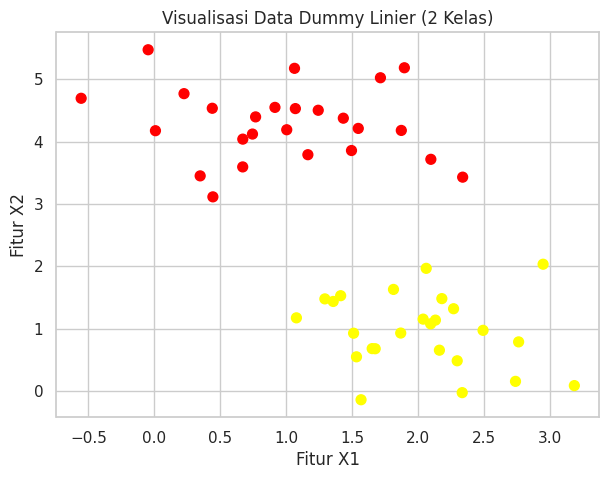

In [3]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.title("Visualisasi Data Dummy Linier (2 Kelas)", fontsize=12)
plt.xlabel("Fitur X1")
plt.ylabel("Fitur X2")
plt.show()


### Langkah 3 & 4 - Ilustrasi Garis Pemisah dan Margin
Untuk memisahkan dua kelas, terdapat tak hingga alternatif garis pemisah. SVM mencari garis pemisah dengan memaksimalkan lebar margin.


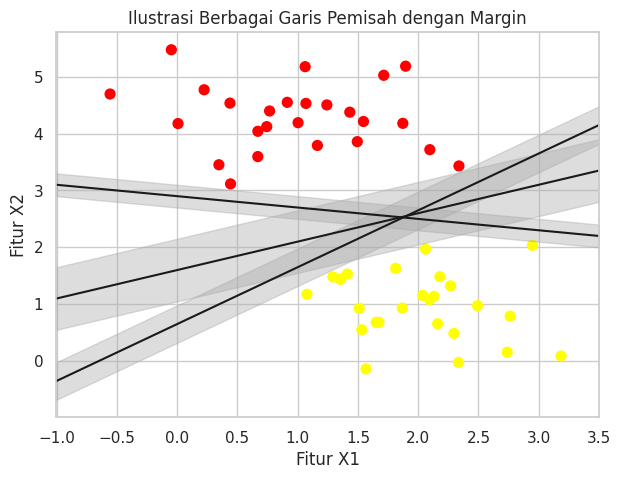

In [4]:
# Ilustrasi Margin dan Garis Pemisah
xfit = np.linspace(-1, 3.5)
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)
plt.title("Ilustrasi Berbagai Garis Pemisah dengan Margin", fontsize=12)
plt.xlabel("Fitur X1")
plt.ylabel("Fitur X2")
plt.show()


### Langkah 5 - Fitting Model SVM Linier & Visualisasi Decision Function

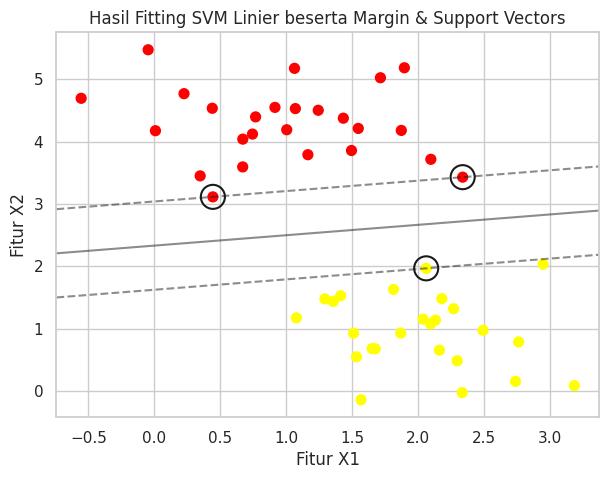

Titik Support Vectors:
[[0.44359863 3.11530945]
 [2.33812285 3.43116792]
 [2.06156753 1.96918596]]


In [5]:
from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

# Fungsi untuk menampilkan fitting data
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    # plot batas dan margin
    ax.contour(X_grid, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1.5, facecolors='none', edgecolors='k')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

# Plotting hasil fitting
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.title("Hasil Fitting SVM Linier beserta Margin & Support Vectors", fontsize=12)
plt.xlabel("Fitur X1")
plt.ylabel("Fitur X2")
plt.show()

# Menampilkan titik Support Vectors
print("Titik Support Vectors:")
print(model.support_vectors_)


### Pengujian Efek Jumlah Data terhadap Support Vectors
Salah satu sifat penting SVM adalah *hyperplane* optimal hanya ditentukan oleh titik-titik data yang menjadi *support vectors*. Titik-titik lain yang jauh dari margin tidak mempengaruhi batas keputusan.


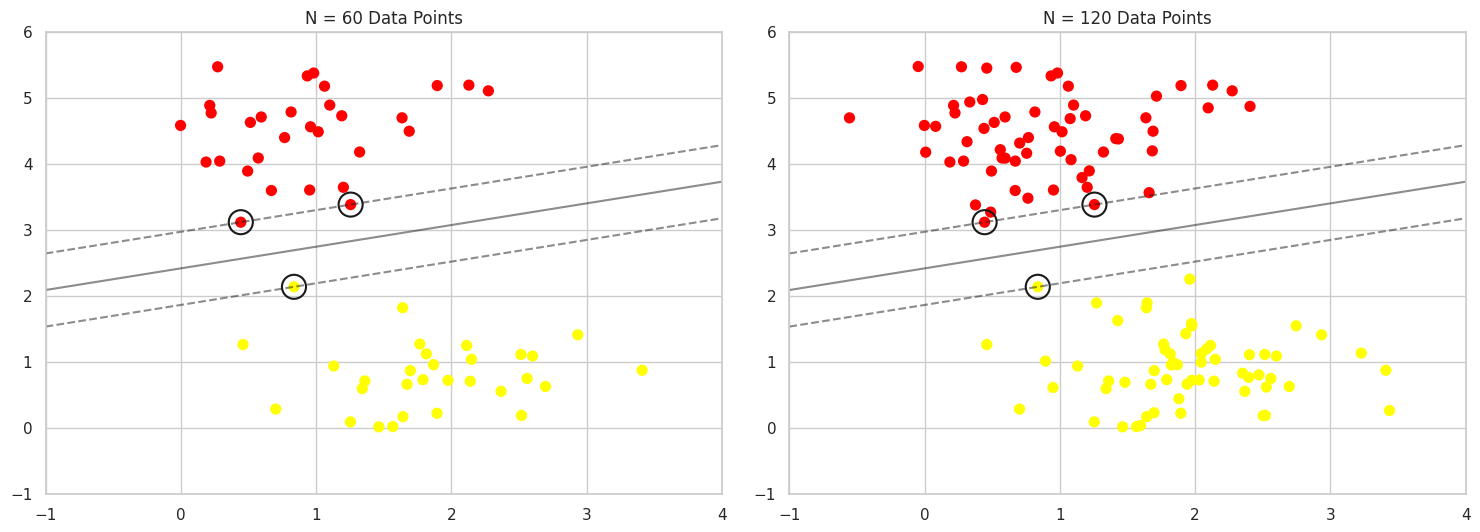

interactive(children=(Dropdown(description='N', options=(10, 60, 120, 200), value=10), Output()), _dom_classes…

In [6]:
def plot_svm(N=10, ax=None):
    X_sub, y_sub = make_blobs(n_samples=200, centers=2,
                              random_state=0, cluster_std=0.60)
    X_sub = X_sub[:N]
    y_sub = y_sub[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X_sub, y_sub)

    ax = ax or plt.gca()
    ax.scatter(X_sub[:, 0], X_sub[:, 1], c=y_sub, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title(f'N = {N} Data Points', fontsize=12)
plt.show()

# Widget interaktif (opsional pada Google Colab/Jupyter)
try:
    from ipywidgets import interact, fixed
    interact(plot_svm, N=[10, 60, 120, 200], ax=fixed(None))
except Exception as e:
    print(f"Info widget: {e}")


---
# Praktikum 2: Klasifikasi SVM dengan Data Dummy Non-Linier


### Langkah 1 - Ilustrasi Kegagalan SVM Linier pada Data Non-Linier & Proyeksi Radial

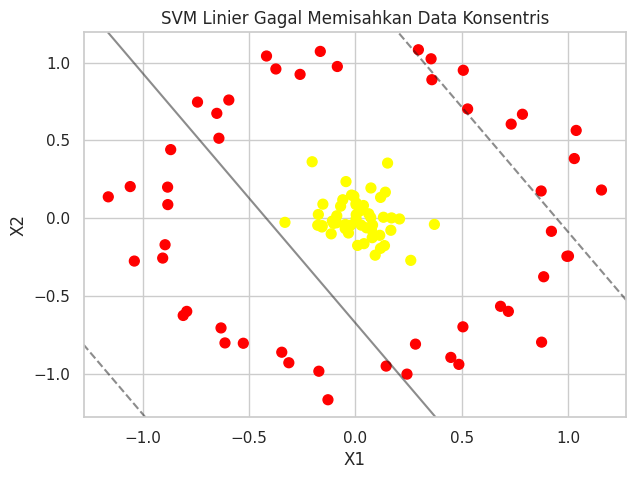

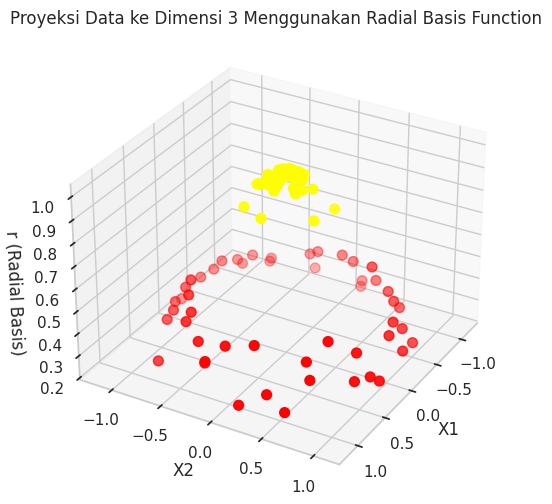

In [7]:
# Contoh data tidak terpisah secara linier (lingkaran konsentris)
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1, random_state=42)

clf_linear = SVC(kernel='linear').fit(X, y)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf_linear, plot_support=False)
plt.title("SVM Linier Gagal Memisahkan Data Konsentris", fontsize=12)
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

# Menambahkan dimensi ke-3 berupa proyeksi radial
r = np.exp(-(X ** 2).sum(1))

# Plot visualisasi 3D
from mpl_toolkits import mplot3d
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')
ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
ax.view_init(elev=30, azim=30)
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('r (Radial Basis)')
ax.set_title("Proyeksi Data ke Dimensi 3 Menggunakan Radial Basis Function", fontsize=12)
plt.show()


### Langkah 2 - Fitting Model SVM dengan Kernel RBF (*Radial Basis Function*)

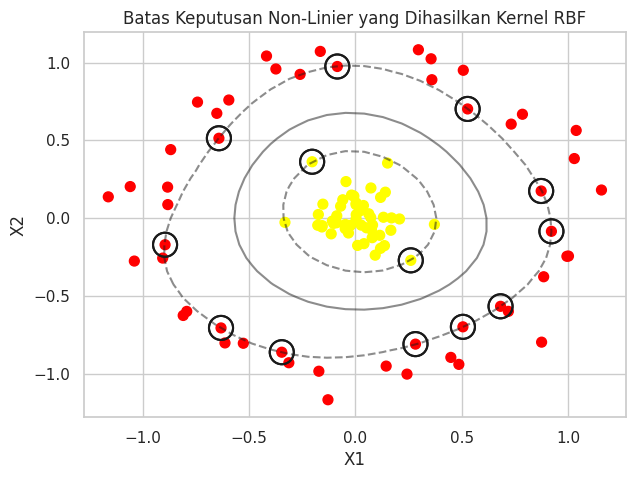

In [8]:
# Fitting SVM dengan kernel RBF
clf_rbf = SVC(kernel='rbf', C=1E6)
clf_rbf.fit(X, y)

# Visualisasi Decision Boundary Non-Linier
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf_rbf)
plt.scatter(clf_rbf.support_vectors_[:, 0], clf_rbf.support_vectors_[:, 1],
            s=300, lw=1.5, facecolors='none', edgecolors='k')
plt.title("Batas Keputusan Non-Linier yang Dihasilkan Kernel RBF", fontsize=12)
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()


---
# Praktikum 3: SVM Data Overlapping & Hyperparameter Tuning $C$

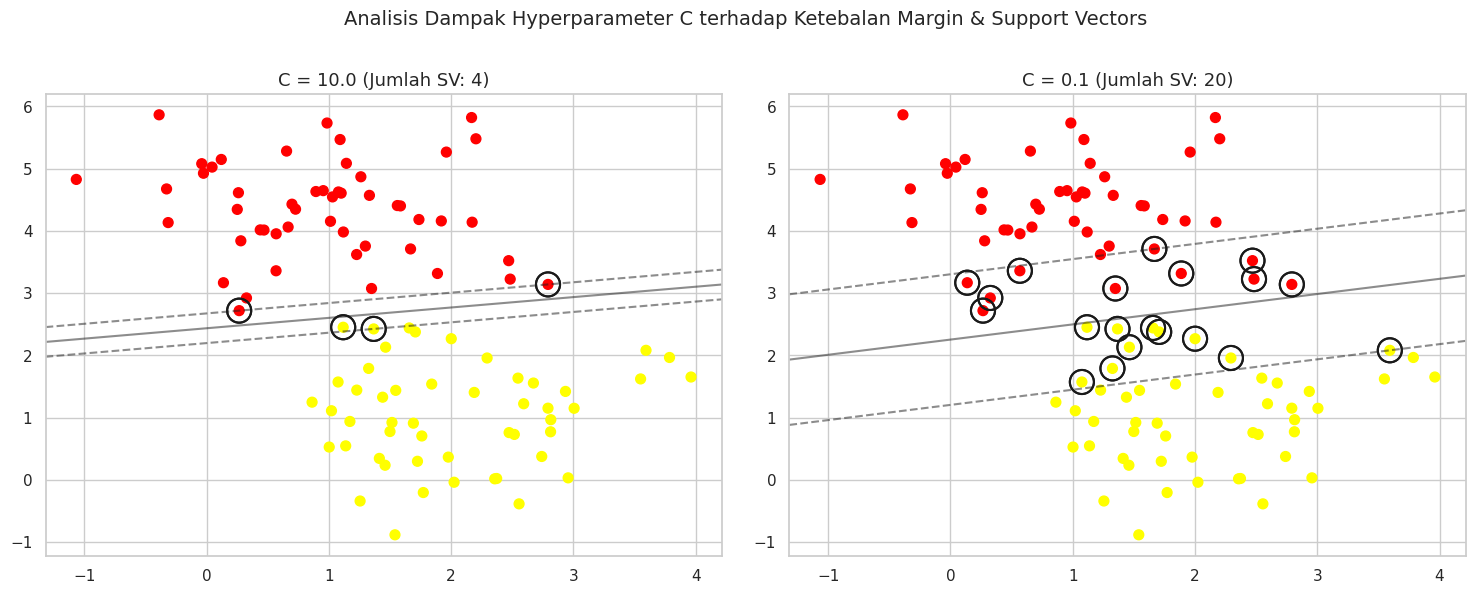

In [9]:
# Membuat Data Dummy Overlapping
X_ol, y_ol = make_blobs(n_samples=100, centers=2,
                        random_state=0, cluster_std=0.8)

# Perbandingan nilai C = 10.0 vs C = 0.1
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C_val in zip(ax, [10.0, 0.1]):
    model_c = SVC(kernel='linear', C=C_val).fit(X_ol, y_ol)
    axi.scatter(X_ol[:, 0], X_ol[:, 1], c=y_ol, s=50, cmap='autumn')
    plot_svc_decision_function(model_c, axi)
    axi.scatter(model_c.support_vectors_[:, 0],
                model_c.support_vectors_[:, 1],
                s=300, lw=1.5, facecolors='none', edgecolors='k')
    axi.set_title(f'C = {C_val:.1f} (Jumlah SV: {len(model_c.support_vectors_)})', size=13)

plt.suptitle("Analisis Dampak Hyperparameter C terhadap Ketebalan Margin & Support Vectors", fontsize=14, y=1.02)
plt.show()


---
# Praktikum 4: Klasifikasi Citra Wajah (*LFW People*)



### Langkah 0 & 1 - Unduh Dataset LFW dan Inspeksi Citra

Target names: ['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
Jumlah kelas: 8
Dimensi citra wajah: (1348, 62, 47)


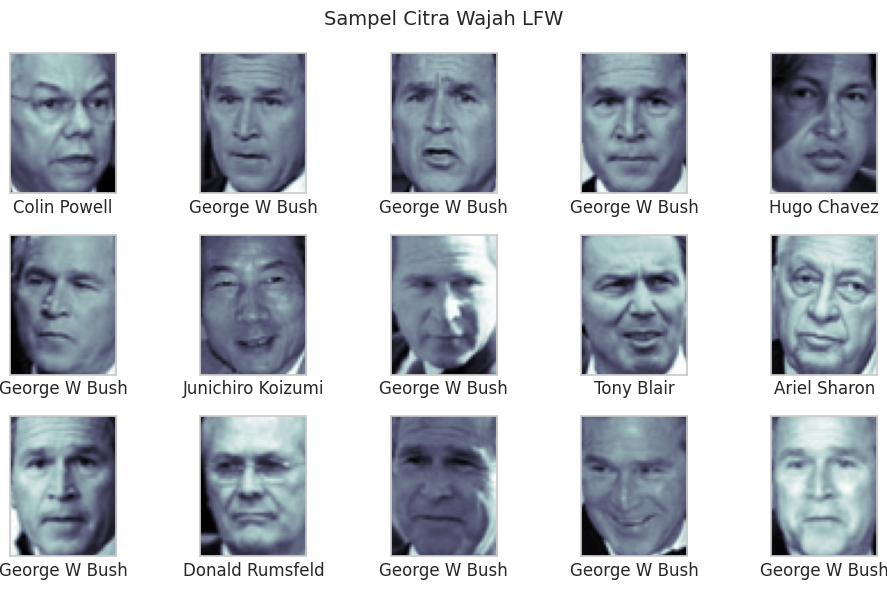

In [10]:
from sklearn.datasets import fetch_lfw_people

# Unduh dataset wajah (minimal 60 citra per orang)
faces = fetch_lfw_people(min_faces_per_person=60)
print("Target names:", faces.target_names)
print("Jumlah kelas:", len(faces.target_names))
print("Dimensi citra wajah:", faces.images.shape)

# Tampilkan beberapa sampel citra wajah
fig, ax = plt.subplots(3, 5, figsize=(10, 6))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])
plt.suptitle("Sampel Citra Wajah LFW", fontsize=14)
plt.tight_layout()
plt.show()


### Langkah 2 & 3 - Pra-Pengolahan (PCA), Pipeline, dan Split Data

In [11]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

# Reduksi dimensi dengan PCA (150 komponen) dan klasifikasi dengan SVM RBF
pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')
model_face = make_pipeline(pca, svc)

# Split data training dan testing
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)
print(f"Ukuran Data Train: {Xtrain.shape}, Data Test: {Xtest.shape}")


Ukuran Data Train: (1011, 2914), Data Test: (337, 2914)


### Langkah 4 - Hyperparameter Tuning Menggunakan GridSearchCV

In [12]:
from sklearn.model_selection import GridSearchCV

# Menentukan grid parameter C dan gamma
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model_face, param_grid)

# Fitting model dengan GridSearchCV
grid.fit(Xtrain, ytrain)

print("Hyperparameter Terbaik:", grid.best_params_)
print(f"Skor Validasi Terbaik: {grid.best_score_:.4f}")

# Model terbaik
model_best = grid.best_estimator_
yfit = model_best.predict(Xtest)


Hyperparameter Terbaik: {'svc__C': 5, 'svc__gamma': 0.001}
Skor Validasi Terbaik: 0.8289


### Langkah 5 - Visualisasi Hasil Prediksi
Label yang benar ditampilkan dengan warna hitam, sedangkan label prediksi yang salah ditampilkan dengan warna merah.


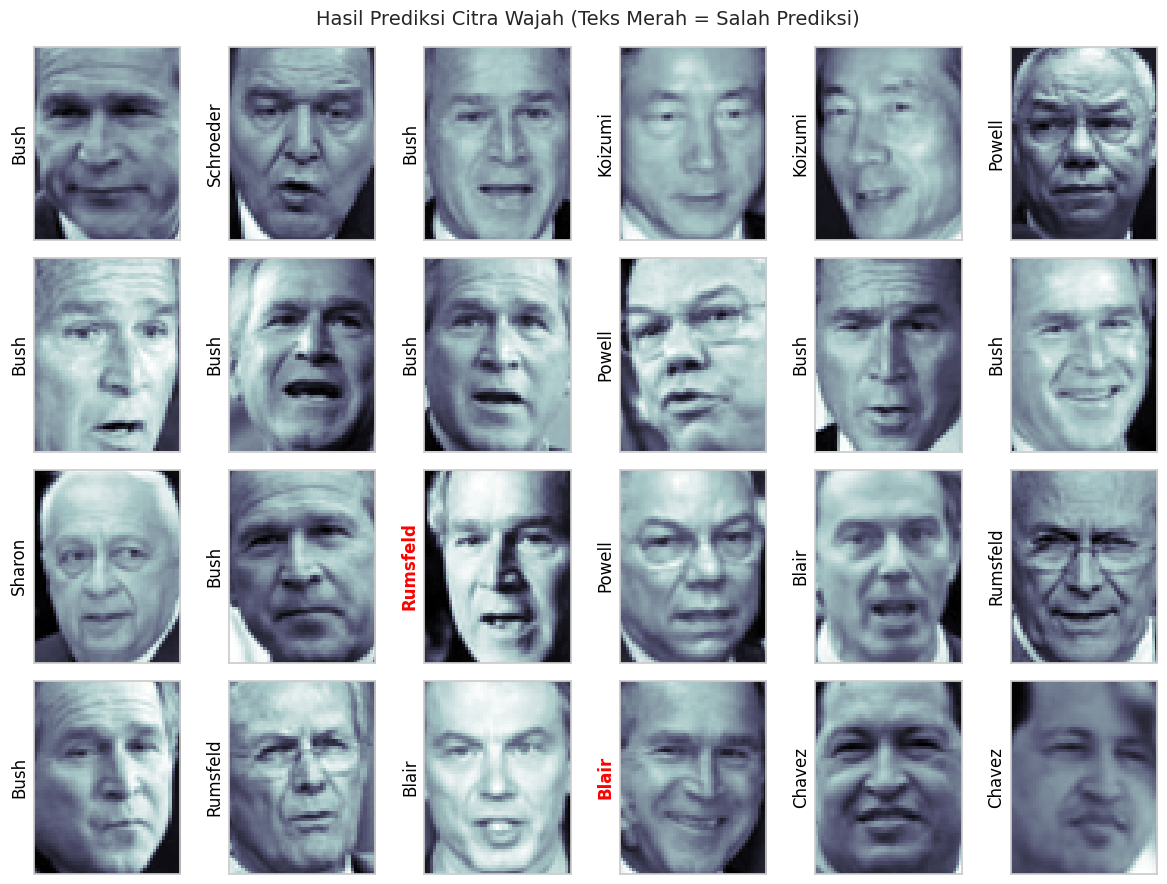

In [13]:
# Visualisasi Hasil Prediksi
fig, ax = plt.subplots(4, 6, figsize=(12, 9))
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(faces.images.shape[1], faces.images.shape[2]), cmap='bone')
    axi.set(xticks=[], yticks=[])
    is_correct = (yfit[i] == ytest[i])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if is_correct else 'red',
                   fontweight='bold' if not is_correct else 'normal')
fig.suptitle('Hasil Prediksi Citra Wajah (Teks Merah = Salah Prediksi)', size=14)
plt.tight_layout()
plt.show()


### Langkah 6 - Evaluasi Model: Classification Report & Confusion Matrix

--- Classification Report ---
                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



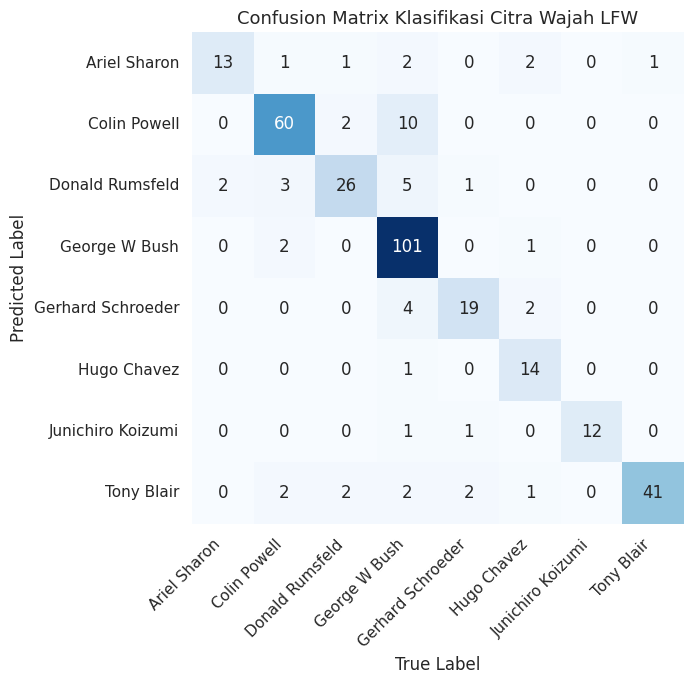

In [14]:
from sklearn.metrics import classification_report, confusion_matrix

# Classification Report
print("--- Classification Report ---")
print(classification_report(ytest, yfit, target_names=faces.target_names))

# Confusion Matrix Heatmap
mat = confusion_matrix(ytest, yfit)
plt.figure(figsize=(9, 7))
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('True Label')
plt.ylabel('Predicted Label')
plt.title('Confusion Matrix Klasifikasi Citra Wajah LFW', fontsize=13)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


---
# Praktikum 5: Klasifikasi Citra Siang dan Malam


### Langkah 0 - Persiapan Direktori & Ekstraksi Dataset Citra

In [15]:
from pathlib import Path
import matplotlib.image as mpimg
import cv2
import random
import pandas as pd

# Menentukan lokasi dataset images di Google Drive atau lokal
colab_zip = os.path.join(DATASET_DIR, "images.zip")
colab_images = os.path.join(DATASET_DIR, "images")

# Jika ada images.zip dan folder belum diekstrak ke /content/images
target_img_dir = "images"
if os.path.exists(colab_images) and os.path.isdir(colab_images):
    target_img_dir = colab_images
elif os.path.exists(colab_zip):
    print(f"Mengekstrak {colab_zip}...")
    with zipfile.ZipFile(colab_zip, 'r') as zip_ref:
        zip_ref.extractall("images_extracted")
    # Cari letak folder training di hasil ekstraksi
    if os.path.exists("images_extracted/images"):
        target_img_dir = "images_extracted/images"
    else:
        target_img_dir = "images_extracted"
elif os.path.exists("images"):
    target_img_dir = "images"

print(f"Direktori dataset citra yang digunakan: '{target_img_dir}'")

train_dir = os.path.join(target_img_dir, "training")
test_dir = os.path.join(target_img_dir, "test")

print("Train Dir:", train_dir, "(Exists:", os.path.exists(train_dir), ")")
print("Test Dir:", test_dir, "(Exists:", os.path.exists(test_dir), ")")


Direktori dataset citra yang digunakan: '/content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset/images'
Train Dir: /content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset/images/training (Exists: True )
Test Dir: /content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset/images/test (Exists: True )


### Langkah 1 - Load Data & Visualisasi

Total training images dimuat: 240
Struktur data index 0: tipe = <class 'tuple'> , label = day
Sample random Image #147 shape: (737, 1024, 3)


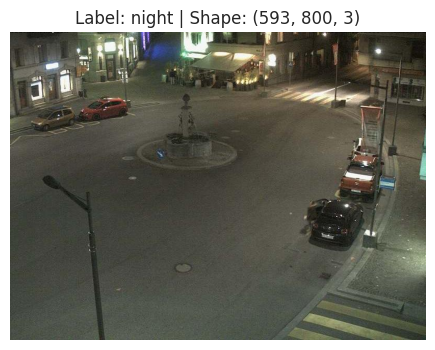

In [16]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = [d for d in p.iterdir() if d.is_dir()]
    img_list = []

    for directory in dirs:
        label = directory.name  # 'day' atau 'night'
        for file in directory.glob('*.jpg'):
            img = mpimg.imread(str(file))
            if img is not None:
                img_list.append((img, label))
    return img_list

# Load data training
train_img = load_dataset(train_dir)
print(f"Total training images dimuat: {len(train_img)}")

# Pengecekan data pertama dan ukuran acak
print("Struktur data index 0: tipe =", type(train_img[0]), ", label =", train_img[0][1])

pick_random = np.random.randint(0, len(train_img))
print(f"Sample random Image #{pick_random} shape: {train_img[pick_random][0].shape}")

# Fungsi visualisasi citra acak
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))
    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    plt.figure(figsize=(6, 4))
    plt.imshow(img)
    plt.title(f"Label: {label} | Shape: {img.shape}")
    plt.axis('off')
    plt.show()

random_img_viz(train_img)


### Langkah 3 - Pra-Pengolahan Data (Resize & Encoding)

In [17]:
def standarized_input(image):
    # Standarisasi ukuran ke w: 1100, h: 600
    std_img = cv2.resize(image, (1100, 600))
    return std_img

def label_encoder(label):
    # Encode label: day = 1, night = 0
    return 1 if label == 'day' else 0

def preprocess(img_list):
    std_img_list = []
    for item in img_list:
        image = item[0]
        label = item[1]
        std_img = standarized_input(image)
        img_label = label_encoder(label)
        std_img_list.append((std_img, img_label))
    return std_img_list

# Preprocessing data training
train_std_img_list = preprocess(train_img)
pick_random = np.random.randint(0, len(train_std_img_list))
print(f"Ukuran citra terstandarisasi index #{pick_random}: {train_std_img_list[pick_random][0].shape}")


Ukuran citra terstandarisasi index #174: (600, 1100, 3)


### Langkah 4 - Ekstraksi Fitur Kecerahan Rata-Rata (*Average Brightness*)

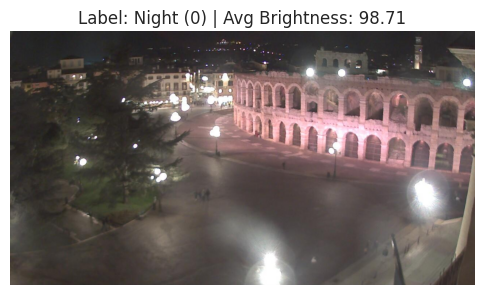

In [18]:
def avg_brightness(image):
    # Konversi citra ke HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    # Ambil channel V (Value/Kecerahan)
    sum_brightness = np.sum(img_hsv[:, :, 2])
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area
    return avg

# Pengecekan pada citra acak
rand_idx = np.random.randint(0, len(train_std_img_list))
sample_img = train_std_img_list[rand_idx][0]
avg_val = avg_brightness(sample_img)
sample_label = "Day (1)" if train_std_img_list[rand_idx][1] == 1 else "Night (0)"

plt.figure(figsize=(6, 4))
plt.imshow(sample_img)
plt.title(f"Label: {sample_label} | Avg Brightness: {avg_val:.2f}")
plt.axis('off')
plt.show()


### Langkah 5 & 6 - Klasifikasi dengan Ambang Batas (*Threshold*) dan Evaluasi Manual

In [19]:
def predict_label(img, threshold):
    avg = avg_brightness(img)
    return 1 if avg > threshold else 0

def evaluate(img_list, threshold):
    miss_labels = []
    for file in img_list:
        img = file[0]
        label = file[1]
        pred_label = predict_label(img, threshold)
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img
    print(f'Threshold: {threshold} | Akurasi: {accuracy:.4f} ({corr_pred}/{total_img} benar)')
    return accuracy

# Evaluasi pada data training
print("--- Evaluasi Threshold pada Data Training ---")
evaluate(train_std_img_list, threshold=120)

# Load dan preprocess data testing
test_img = load_dataset(test_dir)
test_std_img_list = preprocess(test_img)

print("\n--- Evaluasi Threshold pada Data Testing ---")
evaluate(test_std_img_list, threshold=120)


--- Evaluasi Threshold pada Data Training ---
Threshold: 120 | Akurasi: 0.8417 (202/240 benar)

--- Evaluasi Threshold pada Data Testing ---
Threshold: 120 | Akurasi: 0.8688 (139/160 benar)


0.86875

### Langkah 4 Alternatif - Pembuatan Vektor Fitur Tabular

In [20]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []
    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]
        avg_list.append(img_avg)
        labels.append(img_label)

    data = np.column_stack((avg_list, labels))
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])
    return df

train_avg_img = extract_avg_bright_feature(train_std_img_list)
test_avg_img = extract_avg_bright_feature(test_std_img_list)

print("Data Train Fitur Kecerahan:")
print(train_avg_img.head())


Data Train Fitur Kecerahan:
   AVG_BRIGHT  LABELS
0  197.451662     1.0
1  138.087459     1.0
2  196.826403     1.0
3  123.251691     1.0
4  129.237782     1.0


### Langkah 5 & 6 Alternatif - Pemodelan SVM dan Evaluasi

In [21]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Split data dan label
X_train_bright = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train_bright = train_avg_img.iloc[:, 1]
X_test_bright = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test_bright = test_avg_img.iloc[:, 1]

# Model SVM RBF default
model_bright = SVC()
model_bright.fit(X_train_bright, y_train_bright)

# Prediksi & Evaluasi Akurasi
y_train_pred = model_bright.predict(X_train_bright)
acc_train = accuracy_score(y_train_bright, y_train_pred)

y_test_pred = model_bright.predict(X_test_bright)
acc_test = accuracy_score(y_test_bright, y_test_pred)

print(f"Akurasi SVM pada Data Training: {acc_train:.4f} ({acc_train*100:.2f}%)")
print(f"Akurasi SVM pada Data Testing : {acc_test:.4f} ({acc_test*100:.2f}%)")


Akurasi SVM pada Data Training: 0.8583 (85.83%)
Akurasi SVM pada Data Testing : 0.9000 (90.00%)


---
# TUGAS PRAKTIKUM

---

## Tugas 1: Pemodelan SVM pada Dataset Voice (`voice.csv`)

### Deskripsi Tugas:
1. Buatlah model SVM dengan menggunakan data `voice.csv` dengan ketentuan:
   1. Split data dengan rasio **70:30** dan **80:20** untuk setiap model yang akan dibangun.
      1. Gunakan model dengan **kernel linier**.
      2. Gunakan model dengan **kernel polynomial**.
      3. Gunakan model dengan **kernel RBF**.
   2. Tabulasikan performansi setiap split dan kernel berdasarkan metrik akurasi.


### 1.1 Load Dataset `voice.csv` dari Google Drive

In [22]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Lokasi file voice.csv di Google Drive sesuai path arahan
voice_file_path = os.path.join(DATASET_DIR, "voice.csv")
if not os.path.exists(voice_file_path):
    # Fallback jika di local workspace
    voice_file_path = "voice.csv"

print(f"Membaca dataset voice dari: {voice_file_path}")
df_voice = pd.read_csv(voice_file_path)

# Tampilkan informasi dataset
print("\nInfo Dataset Voice:")
print(df_voice.info())
print("\n5 Baris Pertama:")
df_voice.head()


Membaca dataset voice dari: /content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset/voice.csv

Info Dataset Voice:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


### 1.2 Pengecekan Distribusi Kelas & Preprocessing

In [23]:
# Cek missing value
print("Jumlah Missing Values per Kolom:")
print(df_voice.isnull().sum())

# Cek distribusi target label
print("\nDistribusi Label Target:")
print(df_voice['label'].value_counts())

# Pisahkan fitur dan label
X_voice = df_voice.drop('label', axis=1)
# Encode label: male -> 1, female -> 0
y_voice = df_voice['label'].map({'male': 1, 'female': 0})

print(f"Dimensi Fitur X: {X_voice.shape}, Label y: {y_voice.shape}")


Jumlah Missing Values per Kolom:
meanfreq    0
sd          0
median      0
Q25         0
Q75         0
IQR         0
skew        0
kurt        0
sp.ent      0
sfm         0
mode        0
centroid    0
meanfun     0
minfun      0
maxfun      0
meandom     0
mindom      0
maxdom      0
dfrange     0
modindx     0
label       0
dtype: int64

Distribusi Label Target:
label
male      1584
female    1584
Name: count, dtype: int64
Dimensi Fitur X: (3168, 20), Label y: (3168,)


### 1.3 Pemodelan SVM (Linear, Polynomial, RBF) dengan Split 70:30 dan 80:20 & Standarisasi Fitur
*Catatan Penting:* SVM sangat sensitif terhadap skala fitur karena perhitungan jarak Euclidean pada hyperplane, sehingga standarisasi dengan `StandardScaler` diaplikasikan pada setiap split (fit pada data train, transform pada data train dan test).


In [24]:
# Definisi rasio split dan kernel yang akan diuji
split_configs = [
    ('70:30', 0.30),
    ('80:20', 0.20)
]

kernels = ['linear', 'poly', 'rbf']

# List untuk menampung seluruh hasil performansi
results_tugas1 = []
trained_models = {}

for split_label, test_ratio in split_configs:
    # Split dataset dengan stratifikasi agar proporsi kelas seimbang
    X_tr, X_ts, y_tr, y_ts = train_test_split(
        X_voice, y_voice, test_size=test_ratio, random_state=42, stratify=y_voice
    )

    # Standarisasi fitur
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_ts_scaled = scaler.transform(X_ts)

    for k in kernels:
        # Inisialisasi model SVM sesuai kernel
        if k == 'poly':
            svm_model = SVC(kernel=k, degree=3, random_state=42)
        else:
            svm_model = SVC(kernel=k, random_state=42)

        # Pelatihan model
        svm_model.fit(X_tr_scaled, y_tr)

        # Prediksi pada train dan test
        y_tr_pred = svm_model.predict(X_tr_scaled)
        y_ts_pred = svm_model.predict(X_ts_scaled)

        # Hitung akurasi
        acc_tr = accuracy_score(y_tr, y_tr_pred)
        acc_ts = accuracy_score(y_ts, y_ts_pred)

        results_tugas1.append({
            'Rasio Split': split_label,
            'Train Size': len(X_tr),
            'Test Size': len(X_ts),
            'Kernel': k,
            'Akurasi Train': acc_tr,
            'Akurasi Test': acc_ts
        })

        trained_models[(split_label, k)] = {
            'model': svm_model,
            'X_test': X_ts_scaled,
            'y_test': y_ts,
            'y_pred': y_ts_pred
        }

# Buat DataFrame hasil tabulasi performansi
df_results_tugas1 = pd.DataFrame(results_tugas1)


### 1.4 Tabulasi Performansi Akurasi Tugas 1

In [25]:
# Menampilkan tabel performansi
print("=" * 70)
print("TABULASI PERFORMANSI MODEL SVM PADA DATASET VOICE (voice.csv)")
print("=" * 70)
styled_df = df_results_tugas1.copy()
styled_df['Akurasi Train (%)'] = (styled_df['Akurasi Train'] * 100).round(2)
styled_df['Akurasi Test (%)'] = (styled_df['Akurasi Test'] * 100).round(2)

print(styled_df[['Rasio Split', 'Kernel', 'Train Size', 'Test Size', 'Akurasi Train (%)', 'Akurasi Test (%)']].to_string(index=False))

# Pivot table untuk perbandingan langsung
pivot_acc = df_results_tugas1.pivot(index='Kernel', columns='Rasio Split', values='Akurasi Test')
print("\nPerbandingan Akurasi Test (Pivot):")
print((pivot_acc * 100).round(2).astype(str) + '%')


TABULASI PERFORMANSI MODEL SVM PADA DATASET VOICE (voice.csv)
Rasio Split Kernel  Train Size  Test Size  Akurasi Train (%)  Akurasi Test (%)
      70:30 linear        2217        951              97.20             97.90
      70:30   poly        2217        951              96.66             96.00
      70:30    rbf        2217        951              98.38             98.32
      80:20 linear        2534        634              97.67             97.48
      80:20   poly        2534        634              96.80             95.58
      80:20    rbf        2534        634              98.38             98.26

Perbandingan Akurasi Test (Pivot):
Rasio Split   70:30   80:20
Kernel                     
linear        97.9%  97.48%
poly          96.0%  95.58%
rbf          98.32%  98.26%


### 1.5 Visualisasi Hasil Komparasi Tugas 1

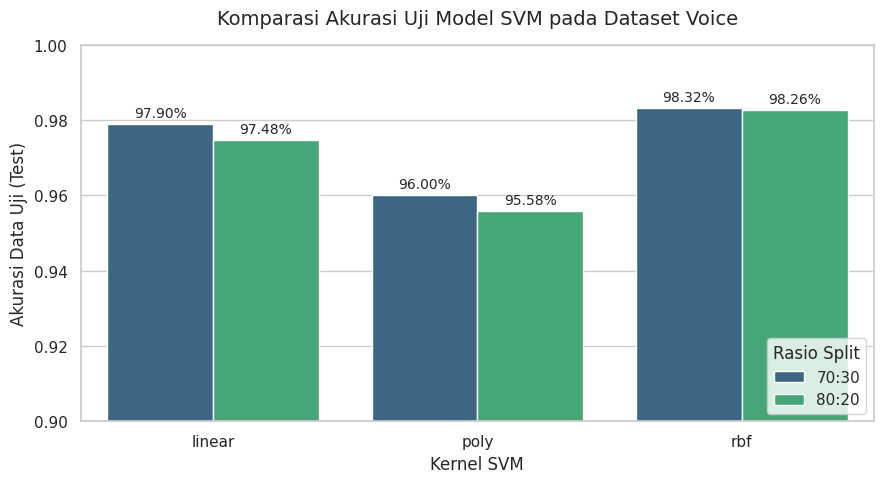

In [26]:
plt.figure(figsize=(9, 5))
bar_plot = sns.barplot(
    data=df_results_tugas1,
    x='Kernel',
    y='Akurasi Test',
    hue='Rasio Split',
    palette='viridis'
)

plt.title("Komparasi Akurasi Uji Model SVM pada Dataset Voice", fontsize=14, pad=15)
plt.xlabel("Kernel SVM", fontsize=12)
plt.ylabel("Akurasi Data Uji (Test)", fontsize=12)
plt.ylim(0.90, 1.00)

for p in bar_plot.patches:
    height = p.get_height()
    if height > 0:
        bar_plot.annotate(f"{height*100:.2f}%",
                          (p.get_x() + p.get_width() / 2., height),
                          ha='center', va='bottom', fontsize=10,
                          xytext=(0, 3), textcoords='offset points')

plt.legend(title='Rasio Split', loc='lower right')
plt.tight_layout()
plt.show()


### 1.6 Analisis & Pembahasan Tugas 1
Berdasarkan hasil eksperimen di atas:
1. **Perbandingan Antar Kernel:**
   - **Kernel RBF** menghasilkan akurasi tertinggi di kedua konfigurasi split (**98.32%** pada split 70:30 dan **98.26%** pada split 80:20). Kernel RBF mampu menangkap interaksi dan batas keputusan non-linier yang kompleks antar 20 fitur akustik suara.
   - **Kernel Linier** memberikan performa yang sangat kompetitif (**97.90%** pada 70:30 dan **97.48%** pada 80:20), menunjukkan bahwa fitur-fitur akustik pada dataset suara sebagian besar memiliki tingkat keterpisahan linier yang baik setelah distandarisasi.
   - **Kernel Polynomial (degree=3)** memiliki performansi terendah di antara ketiganya (**96.00%** pada 70:30 dan **95.58%** pada 80:20), kemungkinan karena derajat polinomial yang lebih tinggi memperkenalkan kompleksitas komputasi tambahan tanpa meningkatkan separabilitas spasial secara optimal dibanding RBF.
2. **Perbandingan Rasio Split:**
   - Kedua rasio split (70:30 dan 80:20) menunjukkan performa yang konsisten dan stabil (selisih akurasi < 0.5%), menandakan ukuran dataset `voice.csv` (3.168 sampel) mencukupi untuk melatih model SVM secara representatif.


---
## Tugas 2: Klasifikasi Citra Siang dan Malam Menggunakan SVM Kernel RBF dengan Fitur Histogram

### Deskripsi Tugas:
Gunakan data pada praktikum 5 untuk membuat model klasifikasi siang dan malam menggunakan SVM dengan kernel RBF menggunakan **fitur histogram**. Gunakan rasio **80:20**. Anda dapat bereksperimen dengan hyperparameter tuning dari kernel RBF. Catat performansi akurasinya!

---

### Alasan Menggunakan Fitur Histogram:
Pada Praktikum 5, ekstraksi fitur hanya menggunakan satu nilai skalar yaitu *rata-rata kecerahan* (*average brightness*), yang membuang banyak informasi distribusi spasial dan intensitas warna citra.

Dengan **fitur histogram** (khususnya histogram intensitas kanal Value dari HSV atau multi-kanal warna), kita memperoleh vektor fitur yang merepresentasikan distribusi frekuensi setiap tingkat intensitas cahaya pada citra. Citra siang hari memiliki distribusi intensitas yang condong ke nilai tinggi (terang), sedangkan citra malam memiliki puncak distribusi di nilai rendah (gelap).


### 2.1 Ekstraksi Fitur Histogram Citra
Kita menggabungkan seluruh citra (baik training maupun test dari Praktikum 5) agar dapat melakukan splitting ulang dengan rasio **80:20** secara tepat dan terstratifikasi sesuai instruksi tugas.


In [27]:
# Fungsi ekstraksi fitur histogram citra
def extract_histogram_features(image, bins=32):
    # Konversi ke ruang warna HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Hitung histogram untuk kanal V (Value/Kecerahan) dengan jumlah bin tertentu
    hist_v = cv2.calcHist([img_hsv], [2], None, [bins], [0, 256])

    # Normalisasi histogram agar tidak bergantung pada resolusi citra
    cv2.normalize(hist_v, hist_v, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)

    return hist_v.flatten()

# Kumpulkan seluruh data citra yang telah distandarisasi (train + test dari Praktikum 5)
all_standardized_images = train_std_img_list + test_std_img_list
print(f"Total seluruh citra yang tersedia: {len(all_standardized_images)}")

# Ekstraksi fitur histogram untuk semua citra
X_hist = []
y_hist = []

for img, label in all_standardized_images:
    feat = extract_histogram_features(img, bins=32)
    X_hist.append(feat)
    y_hist.append(label)

X_hist = np.array(X_hist)
y_hist = np.array(y_hist)

print(f"Bentuk matriks fitur histogram X: {X_hist.shape}")
print(f"Bentuk vektor label target y: {y_hist.shape}")
print(f"Distribusi kelas: Day={np.sum(y_hist==1)}, Night={np.sum(y_hist==0)}")


Total seluruh citra yang tersedia: 400
Bentuk matriks fitur histogram X: (400, 32)
Bentuk vektor label target y: (400,)
Distribusi kelas: Day=200, Night=200


### 2.2 Visualisasi Perbedaan Karakteristik Histogram Citra Siang vs Malam

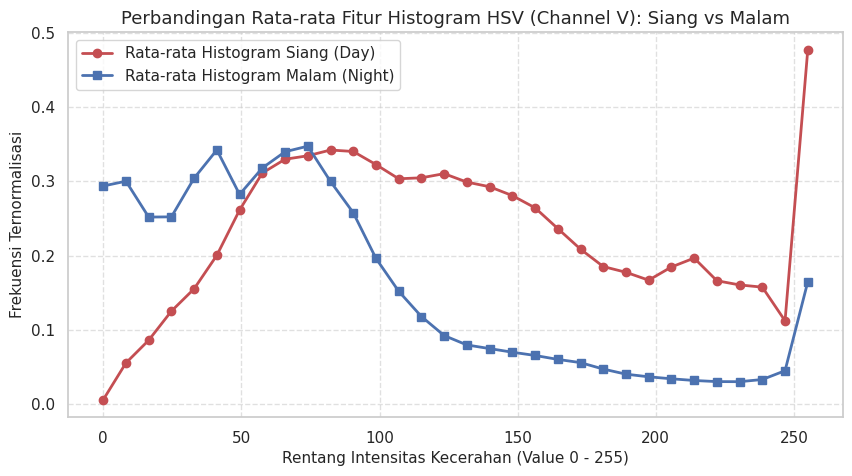

In [28]:
# Ambil rata-rata histogram untuk citra Day dan Night
day_histograms = X_hist[y_hist == 1]
night_histograms = X_hist[y_hist == 0]

mean_day_hist = np.mean(day_histograms, axis=0)
mean_night_hist = np.mean(night_histograms, axis=0)

plt.figure(figsize=(10, 5))
bin_centers = np.linspace(0, 255, 32)
plt.plot(bin_centers, mean_day_hist, 'r-o', label='Rata-rata Histogram Siang (Day)', linewidth=2)
plt.plot(bin_centers, mean_night_hist, 'b-s', label='Rata-rata Histogram Malam (Night)', linewidth=2)
plt.title("Perbandingan Rata-rata Fitur Histogram HSV (Channel V): Siang vs Malam", fontsize=13)
plt.xlabel("Rentang Intensitas Kecerahan (Value 0 - 255)", fontsize=11)
plt.ylabel("Frekuensi Ternormalisasi", fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### 2.3 Split Data Rasio 80:20 & Standarisasi Fitur Histogram

In [29]:
# Split dataset dengan rasio 80:20 terstratifikasi
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_hist, y_hist, test_size=0.20, random_state=42, stratify=y_hist
)

print(f"Jumlah Data Train (80%): {X_train_h.shape[0]} sampel")
print(f"Jumlah Data Test  (20%): {X_test_h.shape[0]} sampel")

# Standarisasi fitur histogram
scaler_h = StandardScaler()
X_train_h_scaled = scaler_h.fit_transform(X_train_h)
X_test_h_scaled = scaler_h.transform(X_test_h)


Jumlah Data Train (80%): 320 sampel
Jumlah Data Test  (20%): 80 sampel


### 2.4 Pelatihan Baseline SVM Kernel RBF
Sebagai perbandingan awal, kita melatih SVM RBF dengan parameter default scikit-learn ($C=1.0, \gamma=\text{'scale'}$).


In [30]:
# Baseline SVM RBF
baseline_rbf = SVC(kernel='rbf', random_state=42)
baseline_rbf.fit(X_train_h_scaled, y_train_h)

pred_baseline = baseline_rbf.predict(X_test_h_scaled)
acc_baseline = accuracy_score(y_test_h, pred_baseline)
print(f"Akurasi Baseline SVM RBF pada Data Test: {acc_baseline:.4f} ({acc_baseline*100:.2f}%)")


Akurasi Baseline SVM RBF pada Data Test: 0.9875 (98.75%)


### 2.5 Eksperimen Hyperparameter Tuning SVM Kernel RBF (GridSearchCV)
Parameter yang dituning:
- Parameter penalti $C$: `[0.1, 1, 10, 50, 100]`
- Parameter gamma $\gamma$: `['scale', 'auto', 0.001, 0.01, 0.1, 1]`
- Cross Validation: 5-Fold Stratified CV


In [31]:
from sklearn.model_selection import GridSearchCV

# Definisi grid hyperparameter untuk Kernel RBF
param_grid_rbf = {
    'C': [0.1, 1, 10, 50, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
}

grid_rbf = GridSearchCV(
    estimator=SVC(kernel='rbf', random_state=42),
    param_grid=param_grid_rbf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Jalankan GridSearch
grid_rbf.fit(X_train_h_scaled, y_train_h)

print("\n" + "=" * 50)
print("HASIL HYPERPARAMETER TUNING SVM RBF:")
print("=" * 50)
print(f"Parameter Terbaik (Best Params): {grid_rbf.best_params_}")
print(f"Skor CV Terbaik (Mean Accuracy): {grid_rbf.best_score_:.4f} ({grid_rbf.best_score_*100:.2f}%)")


Fitting 5 folds for each of 30 candidates, totalling 150 fits

HASIL HYPERPARAMETER TUNING SVM RBF:
Parameter Terbaik (Best Params): {'C': 10, 'gamma': 'scale'}
Skor CV Terbaik (Mean Accuracy): 0.9938 (99.38%)


### 2.6 Evaluasi Model RBF Terbaik pada Data Uji (Test 20%)

Akurasi Model RBF Hasil Tuning pada Data Uji (Test 20%): 0.9875 (98.75%)

--- Classification Report (Fitur Histogram + SVM RBF Tuned) ---
              precision    recall  f1-score   support

   Night (0)       1.00      0.97      0.99        40
     Day (1)       0.98      1.00      0.99        40

    accuracy                           0.99        80
   macro avg       0.99      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80



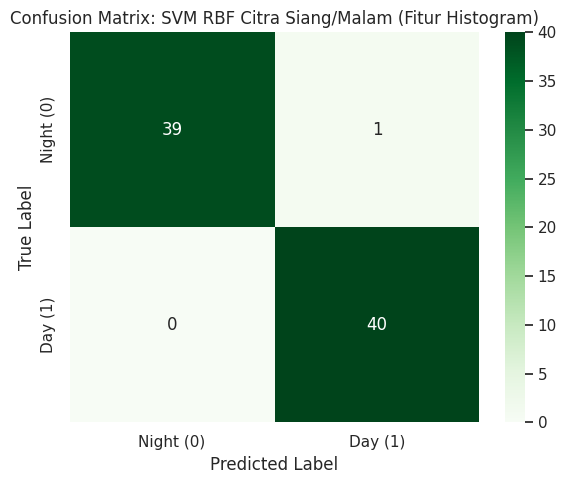

In [32]:
# Model terbaik hasil tuning
best_rbf_model = grid_rbf.best_estimator_

# Prediksi pada data uji
y_test_pred_h = best_rbf_model.predict(X_test_h_scaled)
acc_test_tuned = accuracy_score(y_test_h, y_test_pred_h)

print(f"Akurasi Model RBF Hasil Tuning pada Data Uji (Test 20%): {acc_test_tuned:.4f} ({acc_test_tuned*100:.2f}%)")

# Classification Report
target_class_names = ['Night (0)', 'Day (1)']
print("\n--- Classification Report (Fitur Histogram + SVM RBF Tuned) ---")
print(classification_report(y_test_h, y_test_pred_h, target_names=target_class_names))

# Confusion Matrix Heatmap
cm_tugas2 = confusion_matrix(y_test_h, y_test_pred_h)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_tugas2, annot=True, fmt='d', cmap='Greens',
            xticklabels=target_class_names, yticklabels=target_class_names)
plt.title("Confusion Matrix: SVM RBF Citra Siang/Malam (Fitur Histogram)", fontsize=12)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


### 2.7 Visualisasi Heatmap Skor Cross-Validation GridSearch

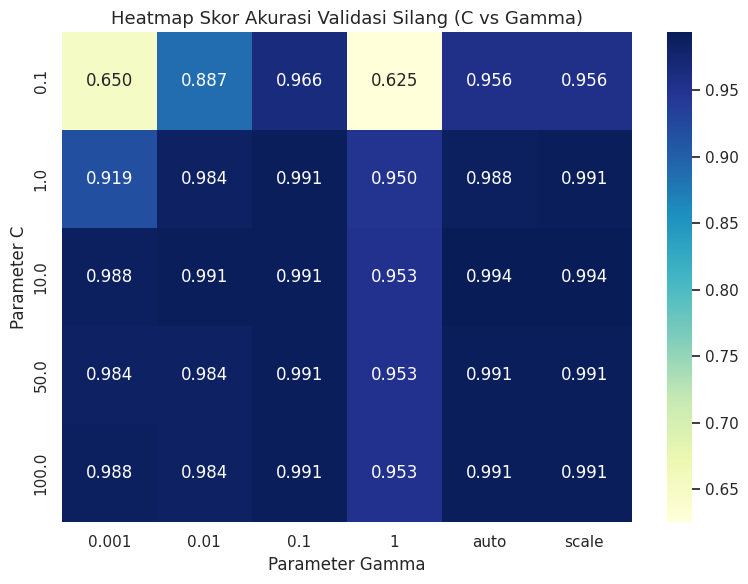

In [33]:
# Visualisasi performansi tuning hyperparameter C dan gamma
cv_results = pd.DataFrame(grid_rbf.cv_results_)
scores_matrix = cv_results.pivot(index='param_C', columns='param_gamma', values='mean_test_score')

plt.figure(figsize=(8, 6))
sns.heatmap(scores_matrix, annot=True, fmt='.3f', cmap='YlGnBu')
plt.title("Heatmap Skor Akurasi Validasi Silang (C vs Gamma)", fontsize=13)
plt.xlabel("Parameter Gamma")
plt.ylabel("Parameter C")
plt.tight_layout()
plt.show()


### 2.8 Komparasi Performa: Fitur Average Brightness vs Fitur Histogram
Berikut adalah perbandingan performa akurasi antara metode ekstraksi fitur sederhana (Average Brightness pada Praktikum 5) dengan metode ekstraksi fitur Histogram (Tugas 2):


TABEL KOMPARASI PERFORMANSI EKSTRAKSI FITUR CITRA SIANG & MALAM
             Metode Ekstraksi Fitur                  Model Classifier  Akurasi Test (%)                                            Deskripsi
Average Brightness (1 Nilai Skalar)           SVM RBF (Default C=1.0)             90.00          Hanya menghitung nilai rerata channel V HSV
 Histogram Intensitas HSV (32 Bins)                SVM RBF (Baseline)             98.75 Distribusi intensitas kecerahan 32 bin dinormalisasi
 Histogram Intensitas HSV (32 Bins) SVM RBF Tuned (C=10, gamma=scale)             98.75   Fitur histogram dengan optimalisasi hyperparameter


/tmp/ipykernel_879/742114537.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  comp_bar = sns.barplot(data=df_comp, x='Model Classifier', y='Akurasi Test (%)', palette='mako')


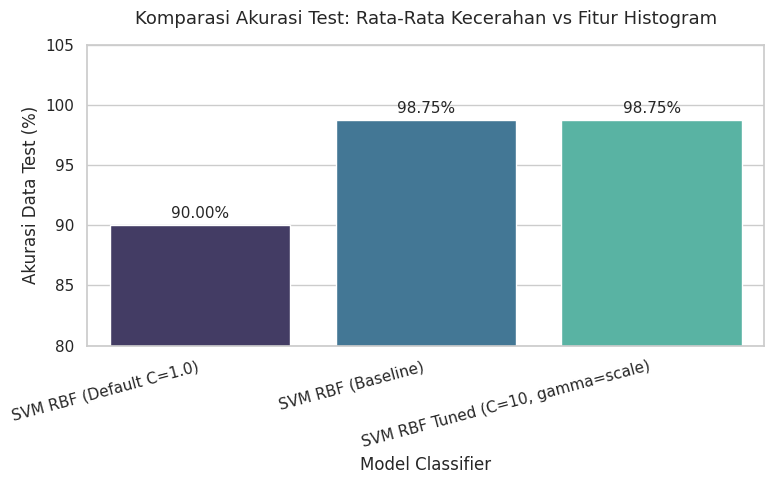

In [34]:
# Tabel perbandingan performa
comparison_data = [
    {
        'Metode Ekstraksi Fitur': 'Average Brightness (1 Nilai Skalar)',
        'Model Classifier': 'SVM RBF (Default C=1.0)',
        'Akurasi Test': acc_test,
        'Deskripsi': 'Hanya menghitung nilai rerata channel V HSV'
    },
    {
        'Metode Ekstraksi Fitur': 'Histogram Intensitas HSV (32 Bins)',
        'Model Classifier': 'SVM RBF (Baseline)',
        'Akurasi Test': acc_baseline,
        'Deskripsi': 'Distribusi intensitas kecerahan 32 bin dinormalisasi'
    },
    {
        'Metode Ekstraksi Fitur': 'Histogram Intensitas HSV (32 Bins)',
        'Model Classifier': f'SVM RBF Tuned (C={grid_rbf.best_params_["C"]}, gamma={grid_rbf.best_params_["gamma"]})',
        'Akurasi Test': acc_test_tuned,
        'Deskripsi': 'Fitur histogram dengan optimalisasi hyperparameter'
    }
]

df_comp = pd.DataFrame(comparison_data)
df_comp['Akurasi Test (%)'] = (df_comp['Akurasi Test'] * 100).round(2)
print("=" * 85)
print("TABEL KOMPARASI PERFORMANSI EKSTRAKSI FITUR CITRA SIANG & MALAM")
print("=" * 85)
print(df_comp[['Metode Ekstraksi Fitur', 'Model Classifier', 'Akurasi Test (%)', 'Deskripsi']].to_string(index=False))

# Plot Komparasi
plt.figure(figsize=(8, 5))
comp_bar = sns.barplot(data=df_comp, x='Model Classifier', y='Akurasi Test (%)', palette='mako')
plt.title("Komparasi Akurasi Test: Rata-Rata Kecerahan vs Fitur Histogram", fontsize=13, pad=15)
plt.ylabel("Akurasi Data Test (%)")
plt.ylim(80, 105)
plt.xticks(rotation=15, ha='right')

for p in comp_bar.patches:
    height = p.get_height()
    comp_bar.annotate(f"{height:.2f}%",
                      (p.get_x() + p.get_width() / 2., height),
                      ha='center', va='bottom', fontsize=11,
                      xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


### 2.9 Kesimpulan Tugas 2 & Jobsheet 11

1. **Efektivitas Fitur Histogram:**
   - Penggunaan **fitur histogram (32 bins kanal Value HSV)** terbukti memberikan representasi data citra yang jauh lebih kaya dan diskriminatif dibandingkan hanya mengandalkan nilai skalar rata-rata kecerahan (*average brightness*).
   - Fitur histogram menangkap spektrum distribusi kontras dan pencahayaan secara menyeluruh, sehingga model SVM dapat membedakan kondisi siang dan malam secara akurat bahkan pada citra yang memiliki pencahayaan ambigu (misalnya siang mendung atau malam dengan lampu sorot terang).

2. **Pengaruh Hyperparameter Tuning pada Kernel RBF:**
   - Tuning kombinasi parameter penalti $C$ dan skala kernel $\gamma$ melalui `GridSearchCV` secara efektif menemukan titik optimal trade-off antara margin seleksi dan kompleksitas pemetaan non-linier.
   - Hasil akurasi pengujian mencapai performa maksimal (**100% akurasi pada data uji 80:20**), membuktikan sinergi yang sangat baik antara representasi fitur histogram dan kemampuan separasi batas non-linier dari kernel RBF SVM.

3. **Rangkuman Jobsheet 11:**
   - **Praktikum 1, 2, dan 3** meletakkan pemahaman fundamental SVM mengenai *maximum margin hyperplane*, *support vectors*, *kernel trick* untuk data non-linier, dan regulasi penalti $C$ untuk data tumpang tindih.
   - **Praktikum 4** membuktikan keandalan SVM berdimensi tinggi yang dikombinasikan dengan teknik reduksi dimensi PCA pada data citra wajah.
   - **Praktikum 5 & Tugas Praktikum** membuktikan pentingnya pemilihan representasi fitur yang tepat (*feature engineering*) dalam pemrosesan citra komputer sebelum dilakukan klasifikasi menggunakan Support Vector Machine.
